Vision Transformer (Transfer Learning)

In [1]:
%pip install medmnist
%pip install torch torchvision torchaudio
%pip install transformers datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


In [2]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torchvision import models
import timm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
from medmnist import BreastMNIST
from medmnist import INFO
import numpy as np
import copy

In [3]:
# BreastMNIST Information
info = INFO['breastmnist']['label']
print(info)

num_classes = len(info.keys())
print(f"Number of classes: {num_classes}")

# Available accelerator
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nThe available device is: {device}")

{'0': 'malignant', '1': 'normal, benign'}
Number of classes: 2

The available device is: cpu


In [4]:
# Resize to 224 x 224 and convert to 3 channels for vit
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# Validation/test transform (must also be converted to 3 channels and resized)
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5]),
])

# Datasets
train_data = BreastMNIST(split='train', download=True, transform=transform)
test_data = BreastMNIST(split='test', download=True, transform=eval_transform)
val_data = BreastMNIST(split='val', download=True, transform=eval_transform)

# Load dataset
train_set = DataLoader(train_data, batch_size=32, shuffle=True)
test_set = DataLoader(test_data, batch_size=64, shuffle=False)
val_set = DataLoader(val_data, batch_size=64, shuffle=False)

100%|██████████| 560k/560k [00:01<00:00, 447kB/s]


In [5]:
# Load pretrained vit model
model = timm.create_model("vit_small_patch16_224", pretrained=True, num_classes=2, drop_rate=0.2)
model = model.to(device)

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

In [6]:
# Training parameters
batch_size = 32
num_epochs = 30             # pretrained models converges faster
learning_rate = 0.000005    # small, to avoid overwriting pretrained weights (typical for ViT fine-tuning)



# Class weights: label 0 (malignant) is the minority class, so it gets a bigger weight
counts = np.bincount(train_data.labels.ravel())
class_weights = torch.tensor(counts.sum() / (2.0 * counts), dtype=torch.float32).to(device)
print("Class counts:", counts, "| weights:", class_weights.cpu().numpy())


criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.05)

# learning rate scheduler
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

Class counts: [147 399] | weights: [1.8571428  0.68421054]


In [ ]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_state = None
best_epoch = 0

for epoch in range(num_epochs):
  model.train()       # training mode
  running_loss = 0
  correct = 0
  total = 0

  for images, labels in train_set:
    images = images.to(device)
    labels = labels.squeeze(1).long().to(device)

    # Reset gradients
    optimizer.zero_grad()

    # Forward pass
    outputs = model(images)

    # Compute loss
    loss = criterion(outputs, labels)

    # Back propagation
    loss.backward()

    # Update weights
    optimizer.step()

    running_loss += loss.item()

    _, predicted = torch.max(outputs, dim=1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  train_losses.append(running_loss / len(train_set))
  train_accuracies.append(correct / total * 100)

  # disables dropout, validation mode
  model.eval()
  val_loss = 0
  val_correct = 0
  val_total = 0

  with torch.no_grad():
    for images, labels in val_set:
        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        val_loss += loss.item()

        _, predicted = torch.max(outputs, dim=1)
        val_total += labels.size(0)
        val_correct += (predicted == labels).sum().item()

  # run ONCE per epoch, after all validation batches
  val_losses.append(val_loss / len(val_set))
  val_accuracies.append(val_correct / val_total * 100)

  scheduler.step()     # update the learning rate once per epoch

  # keep the best model
  if val_losses[-1] < best_val_loss:
    best_val_loss = val_losses[-1]
    best_epoch = epoch + 1
    best_state = copy.deepcopy(model.state_dict())

  print(f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | "
        f"Train Acc: {train_accuracies[-1]:.2f}% | Val Acc: {val_accuracies[-1]:.2f}%")

if best_state is not None:
  model.load_state_dict(best_state)              # restore the best epoch
print(f"\nBest epoch: {best_epoch} (val loss {best_val_loss:.4f})")

Epoch 1/30 | Train Loss: 0.7793 | Val Loss: 0.5994 | Train Acc: 48.35% | Val Acc: 76.92%
Epoch 2/30 | Train Loss: 0.6533 | Val Loss: 0.4887 | Train Acc: 67.77% | Val Acc: 79.49%
Epoch 3/30 | Train Loss: 0.5564 | Val Loss: 0.4257 | Train Acc: 77.29% | Val Acc: 84.62%
Epoch 4/30 | Train Loss: 0.4522 | Val Loss: 0.3815 | Train Acc: 78.57% | Val Acc: 88.46%
Epoch 5/30 | Train Loss: 0.4181 | Val Loss: 0.3535 | Train Acc: 81.14% | Val Acc: 84.62%
Epoch 6/30 | Train Loss: 0.3392 | Val Loss: 0.3344 | Train Acc: 88.28% | Val Acc: 87.18%
Epoch 7/30 | Train Loss: 0.2870 | Val Loss: 0.3038 | Train Acc: 90.29% | Val Acc: 87.18%
Epoch 8/30 | Train Loss: 0.2463 | Val Loss: 0.2927 | Train Acc: 91.21% | Val Acc: 87.18%
Epoch 9/30 | Train Loss: 0.2282 | Val Loss: 0.2820 | Train Acc: 93.22% | Val Acc: 87.18%
Epoch 10/30 | Train Loss: 0.1818 | Val Loss: 0.2773 | Train Acc: 95.24% | Val Acc: 87.18%
Epoch 11/30 | Train Loss: 0.1628 | Val Loss: 0.2627 | Train Acc: 96.15% | Val Acc: 88.46%
Epoch 12/30 | Train

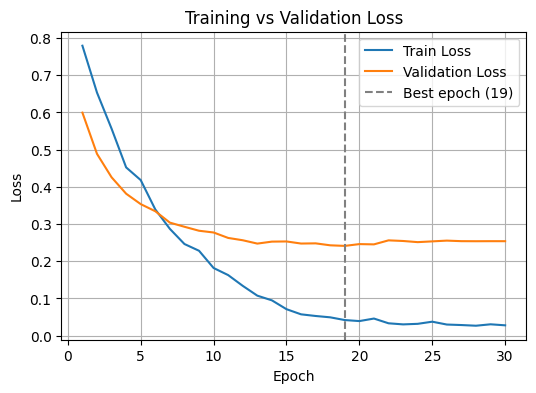

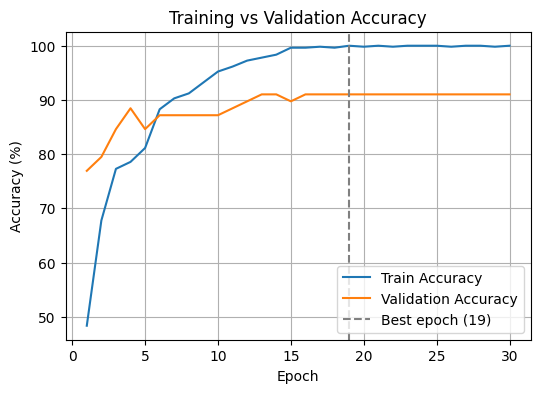

In [ ]:
# Loss graph
plt.figure(figsize=(6,4))
plt.plot(range(1, num_epochs + 1), train_losses, label="Train Loss")
plt.plot(range(1, num_epochs + 1), val_losses, label="Validation Loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy graph
plt.figure(figsize=(6,4))
plt.plot(range(1, num_epochs + 1), train_accuracies, label="Train Accuracy")
plt.plot(range(1, num_epochs + 1), val_accuracies, label="Validation Accuracy")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Testing model on an unseen data
model.load_state_dict(best_state)
model.eval()

correct, total = 0, 0
probs, ys = [], []  # for auc
with torch.no_grad():
    for images, labels in test_set:
        outputs = model(images.to(device))
        preds = outputs.argmax(dim=1).cpu()
        labels = labels.squeeze().long()  # Safer squeeze without dimension index
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        probs += F.softmax(outputs, dim=1)[:, 0].cpu().tolist()   # P(malignant), using outputs directly instead of running model() again
        ys += labels.tolist()

print(f"Test accuracy: {correct / total:.2%}")
print(f"AUC: {roc_auc_score(np.array(ys) == 0, probs):.3f}")

Test accuracy: 89.74%
AUC: 0.935


In [ ]:
# computing performance metrics with confusion matrics using test data
model.load_state_dict(best_state)
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in test_set:
        y_pred += model(images.to(device)).argmax(1).cpu().tolist()
        y_true += labels.squeeze(1).tolist()

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(cmap="Blues")
plt.show()


TP, FN, FP, TN = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print(f"Accuracy: {(TP+TN)/cm.sum():.2%}")
print(f"Sensitivity: {TP/(TP+FN):.2%}")
print(f"Specificity: {TN/(TN+FP):.2%}")